# 06. Сводный индекс и точность


In [1]:
knitr::opts_chunk$set(
  echo = FALSE,
  message = FALSE,
  warning = FALSE,
  fig.align = "center",
  fig.width = 9,
  fig.height = 5
)


# О документе

Три признака (`trait`, `trait_process`, `trait_product`) оцениваются по одной матрице A, затем собираются в сводный индекс с весами. Точность — reliability каждой компоненты.

| | |
|---|---|
| **Данные** | `data/lineage.csv`, `data/measurements.csv` |
| **Цель** | Получить сопоставимый индекс линии, а не три сырых шкалы |
| **Результат** | `overall_index` и отбор изделий с reliability выше порога |


In [2]:
library(rrBLUP)
library(AGHmatrix)
library(Matrix)
library(pedigreeTools)
library(dplyr)
library(ggplot2)
library(tidyr)
library(stringr)
library(e1071)
library(knitr)



Attaching package: ‘dplyr’



The following objects are masked from ‘package:stats’:

    filter, lag



The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union




Attaching package: ‘tidyr’



The following objects are masked from ‘package:Matrix’:

    expand, pack, unpack



In [3]:
z_score_filter <- function(pipeline, threshold) {
  z <- abs((pipeline$trait - mean(pipeline$trait, na.rm = TRUE)) / sd(pipeline$trait, na.rm = TRUE))
  pipeline %>% filter(!(z > threshold))
}

bending <- function(matrix, epsilon) {
  e <- eigen(matrix)
  e$values[e$values < epsilon] <- epsilon
  out <- e$vectors %*% diag(e$values) %*% t(e$vectors)
  rownames(out) <- rownames(matrix)
  colnames(out) <- colnames(matrix)
  out
}

scale_g_to_a <- function(A_matrix, G_matrix) {
  common <- intersect(rownames(G_matrix), rownames(A_matrix))
  G_matrix <- G_matrix[common, common, drop = FALSE]
  A22 <- A_matrix[common, common, drop = FALSE]
  G_matrix * (sum(diag(A22)) / sum(diag(G_matrix)))
}

prepare_ids <- function(lineage, measurements, markers = NULL) {
  ids <- unique(c(measurements$item_id, lineage$item_id, lineage$parent_a, lineage$parent_b))
  if (!is.null(markers)) ids <- unique(c(ids, markers$item_id))
  ids <- ids[ids != 0]
  levels <- as.character(sort(unique(ids)))
  recode <- function(x) as.integer(factor(as.character(x), levels = levels))
  lineage <- lineage %>%
    mutate(
      item_id = recode(item_id),
      parent_a = ifelse(parent_a == 0, 0L, recode(parent_a)),
      parent_b = ifelse(parent_b == 0, 0L, recode(parent_b))
    )
  measurements <- measurements %>% mutate(item_id = recode(item_id))
  if (!is.null(markers)) {
    markers <- markers %>% mutate(item_id = recode(item_id))
  }
  list(lineage = lineage, measurements = measurements, markers = markers, levels = levels)
}

order_lineage <- function(lineage, keep_ids) {
  ped <- editPed(label = lineage$item_id, sire = lineage$parent_a, dam = lineage$parent_b)
  ped <- ped[, c("label", "sire", "dam")]
  names(ped) <- c("item_id", "parent_a", "parent_b")
  ped <- ped %>% filter(item_id %in% keep_ids)
  ped$parent_a[!(ped$parent_a %in% ped$item_id)] <- 0
  ped$parent_b[!(ped$parent_b %in% ped$item_id)] <- 0
  rownames(ped) <- ped$item_id
  ped
}


In [4]:
measurements <- read.csv("data/measurements.csv")
lineage <- read.csv("data/lineage.csv")
measurements <- drop_na(measurements)
prep <- prepare_ids(lineage, measurements)
lineage_bl <- order_lineage(prep$lineage, prep$measurements$item_id)
meas_bl <- prep$measurements %>%
  mutate(event_season = factor(event_season), event_year = factor(event_year))
A <- Amatrix(lineage_bl[, c("item_id", "parent_a", "parent_b")], ploidy = 2)
rownames(A) <- as.character(rownames(A))
meas_bl <- meas_bl[as.character(meas_bl$item_id) %in% rownames(A), ]
meas_bl <- meas_bl[order(match(as.character(meas_bl$item_id), rownames(A))), ]
X <- model.matrix(~ line_age + batch_mass + batch_no + event_season + event_year, data = meas_bl)
Z <- model.matrix(~ 0 + factor(item_id, levels = rownames(A)), data = meas_bl)
colnames(Z) <- rownames(A)

fit_one <- function(y) {
  res <- mixed.solve(y = y, X = X, Z = Z, K = A)
  as.numeric(scale(res$u))
}

idx <- data.frame(
  item_id = as.integer(prep$levels[as.integer(colnames(Z))]),
  est_main = fit_one(meas_bl$trait),
  est_process = fit_one(meas_bl$trait_process),
  est_product = fit_one(meas_bl$trait_product)
)
w <- c(main = 0.45, process = 0.30, product = 0.25)
idx$overall_index <- w["main"] * idx$est_main +
  w["process"] * idx$est_process +
  w["product"] * idx$est_product
head(idx)


Verifying conflicting data... 
Organizing data... 
Your data was chronologically organized with success. 
Constructing matrix A using ploidy = 2 
Completed! Time = 1e-04  minutes 


  item_id    est_main est_process est_product overall_index
1       1  0.17576991  1.00434582  0.06055436   0.395538795
2       2  0.49921813  0.03103969 -0.96596743  -0.007531793
3       3  0.25751376 -0.59283316  0.47405809   0.056545767
4       4  0.57603462 -0.70367377 -0.61860045  -0.106536664
5       5 -0.62049394  0.09197594  2.07819964   0.267920421
6       6  0.06533777 -0.76433111  0.60973016  -0.047464794


# 1. Веса и распределение


In [5]:
w


   main process product 
   0.45    0.30    0.25 


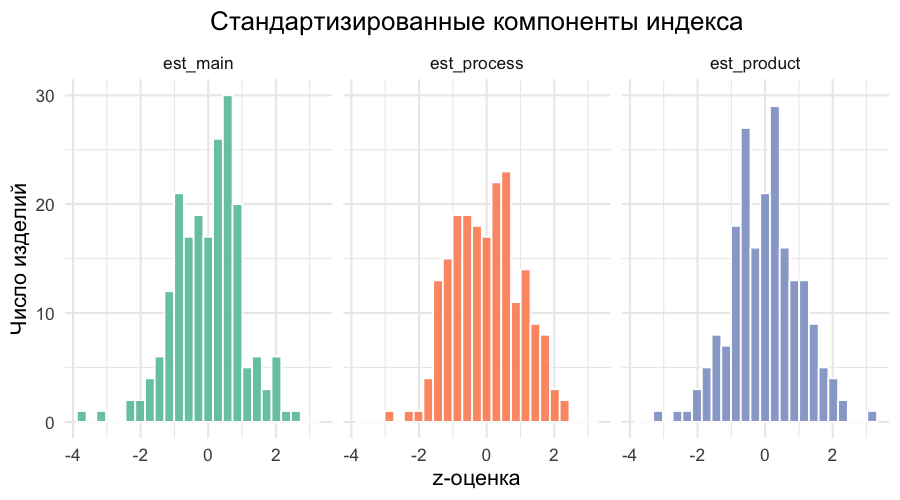

In [6]:
tidyr::pivot_longer(idx, cols = starts_with("est_"), names_to = "component", values_to = "value") %>%
  ggplot(aes(x = value, fill = component)) +
  geom_histogram(bins = 25, color = "white", alpha = 0.9) +
  facet_wrap(~component, ncol = 3) +
  scale_fill_brewer(palette = "Set2", guide = "none") +
  labs(title = "Стандартизированные компоненты индекса", x = "z-оценка", y = "Число изделий") +
  theme_minimal(base_size = 13) +
  theme(plot.title = element_text(hjust = 0.5))


# 2. Точность компоненты `trait`


In [7]:
res_main <- mixed.solve(y = meas_bl$trait, X = X, Z = Z, K = A)
A_inv <- solve(A + diag(1e-6, nrow(A)))
se <- sqrt(res_main$Vu * diag(A_inv))
idx$reliability <- 1 - (as.numeric(se[colnames(Z)])^2 / res_main$Vu)
keep <- idx %>% filter(reliability >= 0.40)
c(n = nrow(idx), n_accurate = nrow(keep), rel_mean = mean(idx$reliability))


         n n_accurate   rel_mean 
200.000000   0.000000  -1.503822 


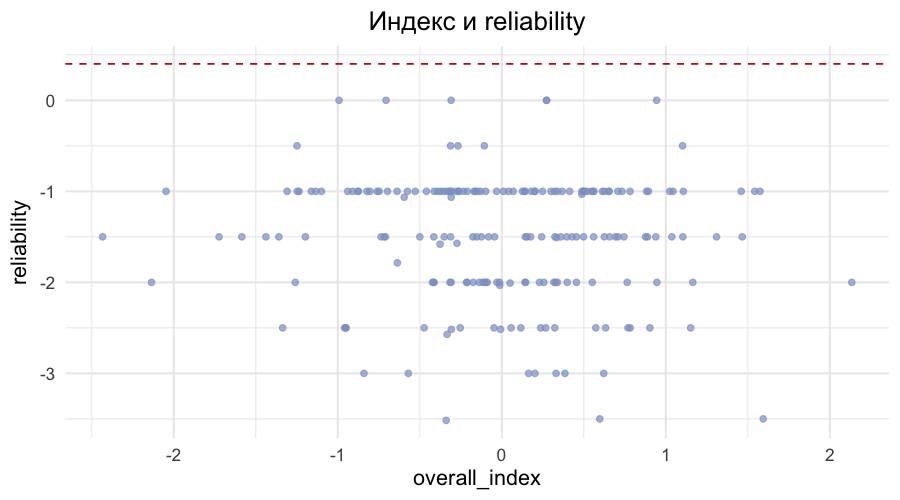

In [8]:
ggplot(idx, aes(x = overall_index, y = reliability)) +
  geom_point(alpha = 0.7, color = "#8DA0CB") +
  geom_hline(yintercept = 0.40, linetype = "dashed", color = "firebrick") +
  labs(title = "Индекс и reliability", x = "overall_index", y = "reliability") +
  theme_minimal(base_size = 13) +
  theme(plot.title = element_text(hjust = 0.5))


# Заключение

Сырые оценки трёх признаков на разных шкалах. После z-стандартизации веса читаются как вклад в сводный индекс. Изделия с низкой reliability лучше не пускать в отбор по индексу: высокое значение может быть шумом, а не качеством линии.
